# Inland Waterways Transportation: Africa & USA

**Domain:** Global Transportation  
**Geographic focus:** Africa (Nigeria, DR Congo, Egypt, Ghana, Mali + 13 comparison countries) and the USA (Mississippi & Ohio River systems)

Africa holds some of the world's largest river systems - the Congo, Niger, Nile and Volta - yet moves only a
small fraction of its freight by water. The United States, by contrast, moves hundreds of millions of tons per year
along the Mississippi and Ohio rivers. This notebook explores that utilization gap using:

| Dataset | Source |
|---|---|
| Container port traffic, GDP, population, liner shipping connectivity | [World Bank Open Data API](https://api.worldbank.org/v2/) |
| US inland waterway tonnage by commodity | [USACE Waterborne Commerce Statistics](https://www.iwr.usace.army.mil/Missions/Navigation/Waterborne-Commerce-Statistics/) |
| African river freight & passengers | [African Development Bank - Transport](https://www.afdb.org/en/topics-and-sectors/sectors/transport) |
| Maritime context | [UNCTAD Review of Maritime Transport](https://unctad.org/topic/transport-and-trade-logistics/review-of-maritime-transport) |
| Population reference | [UN DESA World Population Prospects](https://population.un.org/wpp/) |

The notebook reads the raw CSVs in `data/raw/` directly so it can run before the ETL pipeline; the same metrics are
also produced by `src/transformation/transform.py` and loaded into `data/waterways.db`.

In [1]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
pio.renderers.default = "notebook_connected"
%matplotlib inline

REGION_COLORS = {"Africa": "#E07A1F", "USA": "#1F5AA6"}

## 1. Load the raw data

In [2]:
# Works whether the notebook is launched from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"

container = pd.read_csv(RAW / "container_port_traffic.csv")
gdp = pd.read_csv(RAW / "gdp_data.csv")
lsci = pd.read_csv(RAW / "freight_transport.csv")
population = pd.read_csv(RAW / "population.csv")
infra = pd.read_csv(RAW / "inland_waterway_infrastructure.csv")
us_freight = pd.read_csv(RAW / "us_waterway_freight.csv")
africa_freight = pd.read_csv(RAW / "africa_waterway_freight.csv")

datasets = {
    "container_port_traffic": container,
    "gdp_data": gdp,
    "freight_transport": lsci,
    "population": population,
    "inland_waterway_infrastructure": infra,
    "us_waterway_freight": us_freight,
    "africa_waterway_freight": africa_freight,
}
print(f"Loaded {len(datasets)} datasets from {RAW}")

Loaded 7 datasets from /home/ubuntu/github_repos/Data-Analytic-Data-Engineering/2026-11-20_transportation_africa_usa_inland_waterways/data/raw


## 2. Exploratory data analysis
Shape, column types, summary statistics and missing values for every dataset.

In [3]:
overview = pd.DataFrame({
    name: {"rows": df.shape[0], "columns": df.shape[1], "null_cells": int(df.isna().sum().sum())}
    for name, df in datasets.items()
}).T
overview

,rows,columns,null_cells
container_port_traffic,300,6,142
gdp_data,196,5,0
freight_transport,196,6,40
population,196,5,0
inland_waterway_infrastructure,18,6,0
us_waterway_freight,50,5,0
africa_waterway_freight,32,7,0


In [4]:
for name, df in datasets.items():
    print(f"=== {name}  shape={df.shape}")
    print(df.dtypes.to_string())
    print()

=== container_port_traffic  shape=(300, 6)
country_code      object
country_name      object
iso3              object
year               int64
container_teu    float64
indicator         object

=== gdp_data  shape=(196, 5)
country_code     object
country_name     object
iso3             object
year              int64
gdp_usd         float64

=== freight_transport  shape=(196, 6)
country_code               object
country_name               object
iso3                       object
year                        int64
freight_million_ton_km    float64
indicator                  object

=== population  shape=(196, 5)
country_code    object
country_name    object
iso3            object
year             int64
population       int64

=== inland_waterway_infrastructure  shape=(18, 6)
country              object
iso3                 object
total_waterway_km     int64
navigable_km          int64
major_rivers         object
year                  int64

=== us_waterway_freight  shape=(50, 5)
year    

In [5]:
for name, df in datasets.items():
    print(f"=== {name}")
    display(df.describe(include="all").T.head(12))

=== container_port_traffic


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,300,13,AO,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_name,300,13,Angola,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3,300,13,AGO,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,300.0,NaN,NaN,NaN,2011.74,6.929584,2000.0,2006.0,2012.0,2018.0,2023.0
container_teu,158.0,NaN,NaN,NaN,5120334.392405,13380676.255033,42211.0,454537.5,827780.0,1450891.25,61191458.0
indicator,300,1,Container port traffic (TEU: 20 foot equivalen...,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== gdp_data


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,196,14,AO,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_name,196,14,Angola,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3,196,14,AGO,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,196.0,NaN,NaN,NaN,2016.5,4.041452,2010.0,2013.0,2016.5,2020.0,2023.0
gdp_usd,196.0,NaN,NaN,NaN,1550762957606.958984,5214059981889.194336,11411894723.864,38149115806.032578,68319212880.222549,308866260543.885986,27811517000000.0


=== freight_transport


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,196,14,AO,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_name,196,14,Angola,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3,196,14,AGO,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,196.0,NaN,NaN,NaN,2016.5,4.041452,2010.0,2013.0,2016.5,2020.0,2023.0
freight_million_ton_km,156.0,NaN,NaN,NaN,27.303583,22.012315,4.538329,15.055067,19.54315,31.314609,103.852253
indicator,196,1,Liner shipping connectivity index (maximum val...,196,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (4 outputs left out)

=== us_waterway_freight


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,50.0,NaN,NaN,NaN,2017.3,4.190611,2010.0,2014.0,2018.0,2021.0,2023.0
waterway,50,2,Mississippi River System,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,50,3,Coal,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tonnage_million,50.0,NaN,NaN,NaN,60.456,16.727884,18.7,50.375,65.4,71.175,89.2
direction,50,2,Downstream,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== africa_waterway_freight


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,32,5,Nigeria,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3,32,5,NGA,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
waterway,32,4,Niger River,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,32.0,NaN,NaN,NaN,2018.625,2.459347,2015.0,2016.75,2018.5,2021.0,2022.0
freight_thousand_tons,32.0,NaN,NaN,NaN,1942.5,1312.935642,350.0,1015.0,1650.0,2562.5,4350.0
passengers_thousand,32.0,NaN,NaN,NaN,6533.4375,4615.80008,880.0,2712.5,5400.0,9550.0,14500.0
ports_count,32.0,NaN,NaN,NaN,13.53125,7.170659,4.0,7.75,13.0,19.0,25.0


In [6]:
null_counts = pd.concat(
    {name: df.isna().sum() for name, df in datasets.items()}, names=["dataset", "column"]
)
null_counts[null_counts > 0].to_frame("null_count")

,,null_count
dataset,column,
container_port_traffic,container_teu,142
freight_transport,freight_million_ton_km,40


**EDA notes**

* `container_port_traffic.csv` covers 2000-2023, but World Bank TEU values are only populated from about 2010 onwards,
  so null years are dropped before analysis.
* `freight_transport.csv` stores the *Liner Shipping Connectivity Index* (World Bank `IS.SHP.GCNW.XQ`) in the
  `freight_million_ton_km` column. It is a maritime connectivity proxy and is sparse for some countries.
* The infrastructure, USACE and AfDB tables are complete; the Ohio River series in the USACE extract begins in 2020.

## 3. Cleaning & feature engineering
Mirror of the transformation stage: type casting, null removal, regions, and per-capita / utilization metrics.

In [7]:
ISO2_TO_ISO3 = {"US": "USA", "NG": "NGA", "CD": "COD", "EG": "EGY", "ZA": "ZAF", "GH": "GHA", "ET": "ETH",
                "KE": "KEN", "CM": "CMR", "SN": "SEN", "CI": "CIV", "TZ": "TZA", "MZ": "MOZ", "AO": "AGO",
                "ML": "MLI", "GN": "GIN", "SD": "SDN", "ZM": "ZMB"}
LAND_AREA_SQ_KM = {"USA": 9147420, "NGA": 910770, "COD": 2267050, "EGY": 995450, "ZAF": 1213090,
                   "GHA": 227540, "ETH": 1128571, "KEN": 569140, "CMR": 472710, "SEN": 192530,
                   "CIV": 318000, "TZA": 885800, "MOZ": 786380, "AGO": 1246700, "MLI": 1220190,
                   "GIN": 245720, "SDN": 1765048, "ZMB": 743390}

def region_of(iso3):
    return "USA" if iso3 == "USA" else "Africa"

def clean_wb(df, value_col):
    out = df.copy()
    out[value_col] = pd.to_numeric(out[value_col], errors="coerce")
    out = out.dropna(subset=[value_col]).drop_duplicates(["iso3", "year"])
    out["year"] = out["year"].astype(int)
    out["region"] = out["iso3"].map(region_of)
    return out

container_c = clean_wb(container, "container_teu")
gdp_c = clean_wb(gdp, "gdp_usd")
pop_c = clean_wb(population, "population")
lsci_c = clean_wb(lsci.rename(columns={"freight_million_ton_km": "lsci"}), "lsci")

infra_c = infra.copy()
infra_c["region"] = infra_c["iso3"].map(region_of)
infra_c["land_area_sq_km"] = infra_c["iso3"].map(LAND_AREA_SQ_KM)
infra_c["waterway_density"] = infra_c["navigable_km"] / (infra_c["land_area_sq_km"] / 1000)

us_c = us_freight.copy()
us_c["freight_thousand_tons"] = us_c["tonnage_million"] * 1000

# Annual waterway freight per country (thousand tons)
waterway_freight = pd.concat([
    us_c.groupby("year", as_index=False)["freight_thousand_tons"].sum().assign(iso3="USA"),
    africa_freight.groupby(["iso3", "year"], as_index=False)["freight_thousand_tons"].sum(),
], ignore_index=True)

metrics = (waterway_freight
           .merge(infra_c[["iso3", "country", "navigable_km", "waterway_density", "region"]], on="iso3", how="left")
           .merge(pop_c[["iso3", "year", "population"]], on=["iso3", "year"], how="left")
           .merge(gdp_c[["iso3", "year", "gdp_usd"]], on=["iso3", "year"], how="left"))
metrics["utilization_ratio"] = metrics["freight_thousand_tons"] * 1000 / metrics["navigable_km"]
metrics["freight_per_1000_pop"] = metrics["freight_thousand_tons"] * 1000 / (metrics["population"] / 1000)
metrics.tail()

,year,freight_thousand_tons,iso3,country,navigable_km,waterway_density,region,population,gdp_usd,utilization_ratio,freight_per_1000_pop
41,2018,1410.0,NGA,Nigeria,3000,3.293916,Africa,204938755.0,4.217393e+11,470.000000,6.880104
42,2019,1380.0,NGA,Nigeria,3000,3.293916,Africa,209485641.0,6.682200e+11,460.000000,6.587564
43,2020,1150.0,NGA,Nigeria,3000,3.293916,Africa,213996181.0,5.985868e+11,383.333333,5.373928
44,2021,1290.0,NGA,Nigeria,3000,3.293916,Africa,218529286.0,6.091477e+11,430.000000,5.903099
45,2022,1450.0,NGA,Nigeria,3000,3.293916,Africa,223150896.0,6.469503e+11,483.333333,6.497845


## 4. Visualization 1 - Navigable waterway km by country (Africa vs USA)

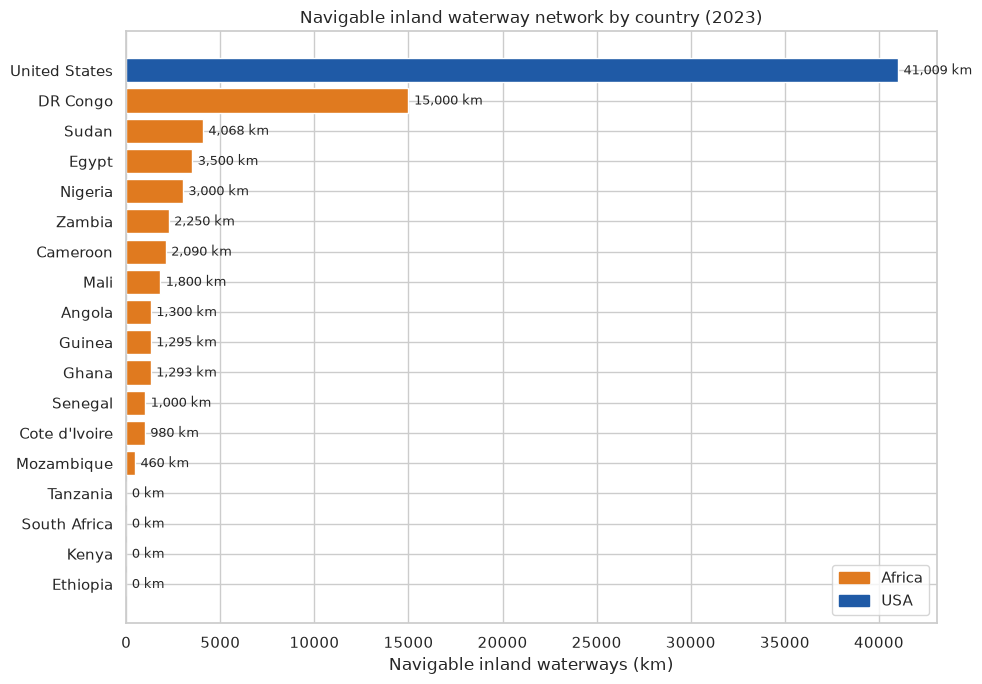

Africa (17 countries): 38,036 navigable km | USA: 41,009 navigable km (93% of the US network)


In [8]:
v1 = infra_c.sort_values("navigable_km", ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(v1["country"], v1["navigable_km"], color=v1["region"].map(REGION_COLORS))
for y, (km, total) in enumerate(zip(v1["navigable_km"], v1["total_waterway_km"])):
    ax.text(km + 300, y, f"{km:,.0f} km", va="center", fontsize=9)
ax.set_xlabel("Navigable inland waterways (km)")
ax.set_title("Navigable inland waterway network by country (2023)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in REGION_COLORS.values()]
ax.legend(handles, REGION_COLORS.keys(), loc="lower right")
plt.tight_layout()
plt.show()

africa_total = infra_c.loc[infra_c.region == "Africa", "navigable_km"].sum()
usa_total = infra_c.loc[infra_c.region == "USA", "navigable_km"].sum()
print(f"Africa (17 countries): {africa_total:,.0f} navigable km | USA: {usa_total:,.0f} navigable km "
      f"({africa_total / usa_total:.0%} of the US network)")

**Insight:** The US network (41,009 km) is the single largest, but the 17 African countries together hold about
38,000 navigable km, or 93% of the US network. DR Congo alone has 15,000 km - over a third of the US figure -
and its waterway density (navigable km per 1,000 sq km) actually exceeds that of the United States.
Nigeria stands out for a low navigable share: only ~35% of its 8,600 km is navigable year-round.
Four countries (South Africa, Ethiopia, Kenya, Tanzania) have no commercially navigable inland waterways.

## 5. Visualization 2 - US Mississippi River System freight tonnage by commodity (2010-2023)

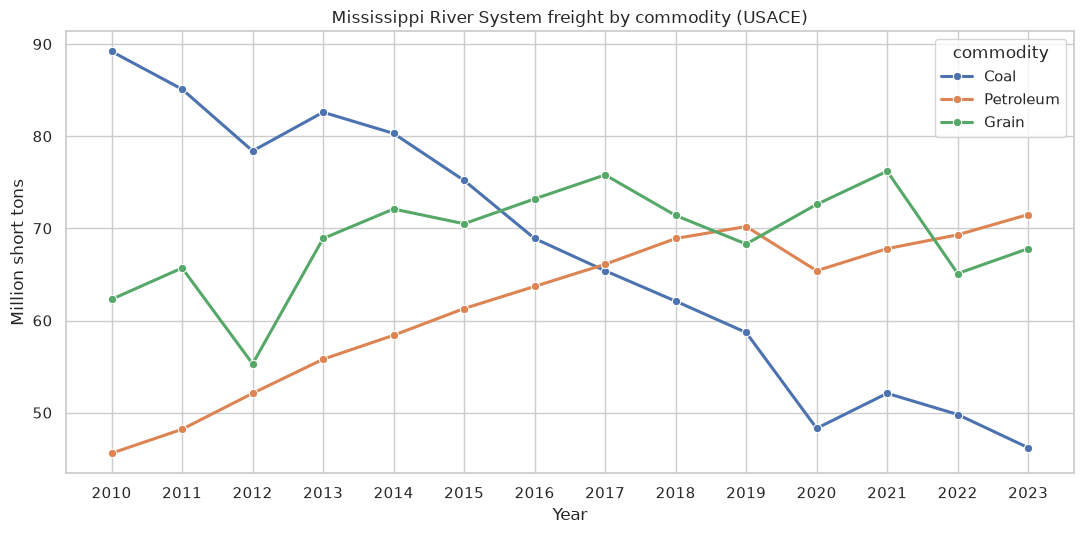

commodity
Coal        -48.2
Grain         8.8
Petroleum    56.8


In [9]:
v2 = us_c[us_c["waterway"] == "Mississippi River System"]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(data=v2, x="year", y="tonnage_million", hue="commodity", marker="o", linewidth=2.2, ax=ax)
ax.set_title("Mississippi River System freight by commodity (USACE)")
ax.set_ylabel("Million short tons")
ax.set_xlabel("Year")
ax.set_xticks(range(2010, 2024))
plt.tight_layout()
plt.show()

change = v2.pivot_table(index="commodity", columns="year", values="tonnage_million")
print((change[2023] / change[2010] - 1).mul(100).round(1).rename("% change 2010-2023").to_string())

**Insight:** The commodity mix on the Mississippi has shifted sharply. Coal tonnage roughly halved between 2010 and
2023 as US power generation moved away from coal, while petroleum products grew by over 50% and became the
largest commodity. Grain stays within a 55-76 Mt band, driven by harvest size and export demand. Total system
volume remained near ~185-210 Mt, showing a resilient, diversified corridor.

## 6. Visualization 3 - Africa waterway freight by country and waterway

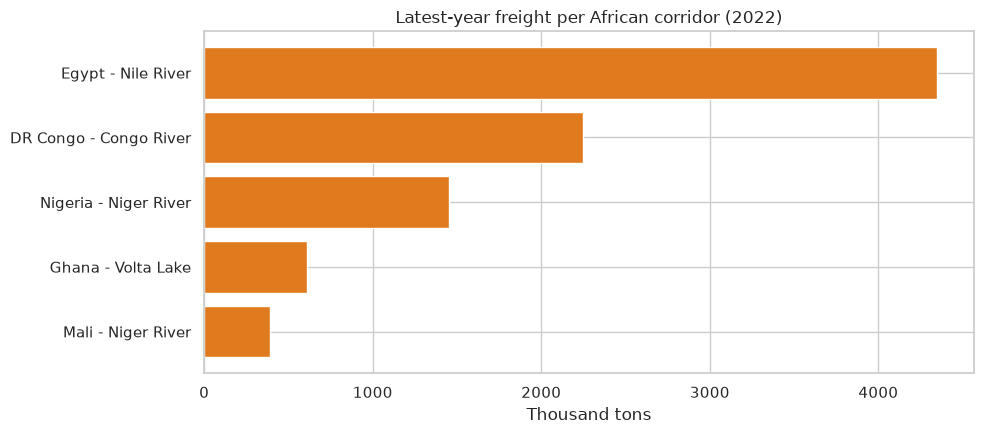

In [10]:
africa_freight["label"] = africa_freight["country"] + " - " + africa_freight["waterway"]
fig = px.bar(
    africa_freight.sort_values("year"), x="year", y="freight_thousand_tons", color="label",
    barmode="group", title="African inland waterway freight by country & waterway (thousand tons)",
    labels={"freight_thousand_tons": "Freight (thousand tons)", "year": "Year", "label": "Corridor"},
)
fig.update_layout(height=500, legend_title_text="Country - waterway")
fig.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
latest = africa_freight.sort_values("year").groupby("label").tail(1).sort_values("freight_thousand_tons")
ax.barh(latest["label"], latest["freight_thousand_tons"], color="#E07A1F")
ax.set_title("Latest-year freight per African corridor (2022)")
ax.set_xlabel("Thousand tons")
plt.tight_layout()
plt.show()

**Insight:** The Nile in Egypt is Africa's busiest freight waterway (4.35 Mt in 2022), followed by the Congo River
(2.25 Mt) and the Niger in Nigeria (1.45 Mt). Every corridor dipped in 2020 (COVID-19) and recovered to new highs by
2022. Even so, the whole African sample moves about 9 Mt per year - **only about 5% of the Mississippi River System
alone**.

## 7. Visualization 4 - GDP vs container port traffic (by region)

In [11]:
v4 = container_c.merge(gdp_c[["iso3", "year", "gdp_usd"]], on=["iso3", "year"])
v4 = v4.merge(infra_c[["iso3", "navigable_km"]], on="iso3", how="left")
v4["navigable_km"] = v4["navigable_km"].fillna(0)
fig = px.scatter(
    v4, x="gdp_usd", y="container_teu", color="region", hover_name="country_name",
    size=np.sqrt(v4["navigable_km"] + 100), log_x=True, log_y=True,
    color_discrete_map=REGION_COLORS, animation_frame=None,
    title="GDP vs container port traffic, 2010-2023 (bubble size = navigable waterway km)",
    labels={"gdp_usd": "GDP (current US$, log)", "container_teu": "Container traffic (TEU, log)"},
)
fig.update_layout(height=550)
fig.show()

r = np.corrcoef(np.log10(v4["gdp_usd"]), np.log10(v4["container_teu"]))[0, 1]
print(f"Correlation of log GDP vs log TEU across {len(v4)} country-years: r = {r:.2f}")

Correlation of log GDP vs log TEU across 158 country-years: r = 0.87


**Insight:** Container throughput scales almost linearly with economic size on a log-log scale (strong positive
correlation). The US sits in the top-right corner, about 1-2 orders of magnitude above any African economy.
Egypt handles the most containers in the African sample (about 7.6M TEU in 2022) thanks to Suez Canal transhipment hubs, whereas DR Congo -
with the continent's largest river network - has very low container traffic, highlighting the missing link between
river networks and seaport logistics.

## 8. Visualization 5 - Correlation matrix across freight metrics

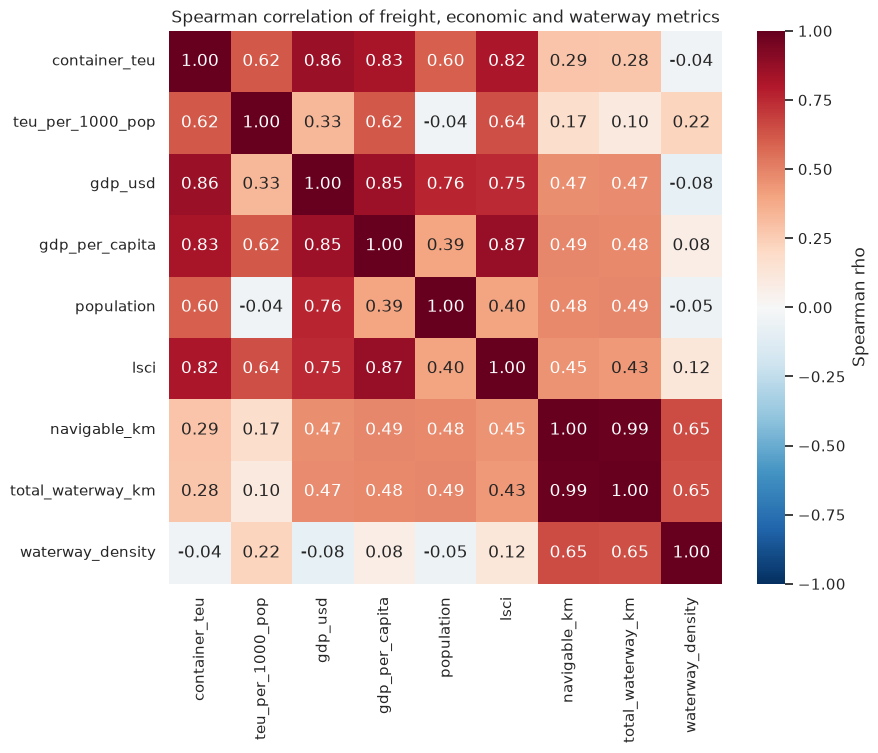

In [12]:
corr_frame = (container_c[["iso3", "year", "container_teu"]]
              .merge(gdp_c[["iso3", "year", "gdp_usd"]], on=["iso3", "year"])
              .merge(pop_c[["iso3", "year", "population"]], on=["iso3", "year"])
              .merge(lsci_c[["iso3", "year", "lsci"]], on=["iso3", "year"], how="left")
              .merge(infra_c[["iso3", "navigable_km", "total_waterway_km", "waterway_density"]], on="iso3", how="left"))
corr_frame["gdp_per_capita"] = corr_frame["gdp_usd"] / corr_frame["population"]
corr_frame["teu_per_1000_pop"] = corr_frame["container_teu"] / (corr_frame["population"] / 1000)
cols = ["container_teu", "teu_per_1000_pop", "gdp_usd", "gdp_per_capita", "population",
        "lsci", "navigable_km", "total_waterway_km", "waterway_density"]
corr = corr_frame[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman rho"})
ax.set_title("Spearman correlation of freight, economic and waterway metrics")
plt.tight_layout()
plt.show()

**Insight:** Container traffic correlates most strongly with GDP and liner shipping connectivity - maritime trade
follows economic scale and carrier networks. Waterway length and density show only weak correlation with TEU
volumes: having rivers does not by itself generate trade. Infrastructure must be connected to ports, rail and
logistics services before it translates into freight.

## 9. Visualization 6 - Waterway utilization index by country

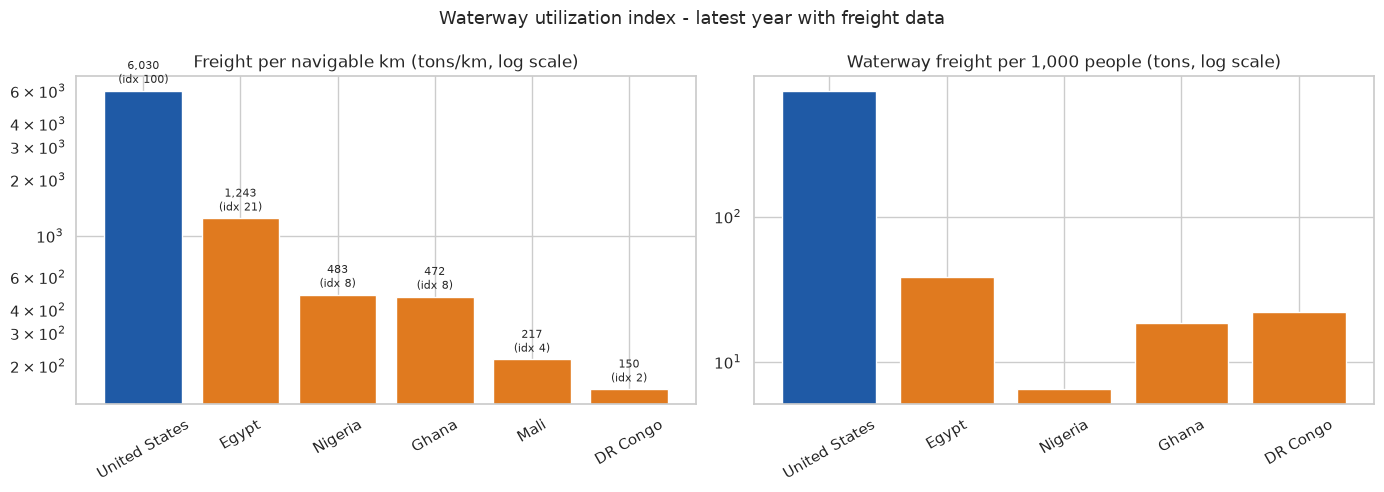

,country,year,freight_thousand_tons,navigable_km,utilization_ratio,utilization_index,freight_per_1000_pop
13,United States,2023,247300.0,41009,6030.4,100.0,734.4
29,Egypt,2022,4350.0,3500,1242.9,20.6,38.6
45,Nigeria,2022,1450.0,3000,483.3,8.0,6.5
33,Ghana,2022,610.0,1293,471.8,7.8,18.4
37,Mali,2022,390.0,1800,216.7,3.6,NaN
21,DR Congo,2022,2250.0,15000,150.0,2.5,22.0


In [13]:
latest_year = metrics.groupby("iso3")["year"].transform("max")
v6 = metrics[metrics["year"] == latest_year].copy()
v6["utilization_index"] = 100 * v6["utilization_ratio"] / v6["utilization_ratio"].max()
v6 = v6.sort_values("utilization_ratio", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(v6["country"], v6["utilization_ratio"], color=v6["region"].map(REGION_COLORS))
axes[0].set_yscale("log")
axes[0].set_title("Freight per navigable km (tons/km, log scale)")
axes[0].tick_params(axis="x", rotation=30)
for i, (val, idx) in enumerate(zip(v6["utilization_ratio"], v6["utilization_index"])):
    axes[0].text(i, val * 1.1, f"{val:,.0f}\n(idx {idx:.0f})", ha="center", fontsize=8)

pc = v6.dropna(subset=["freight_per_1000_pop"])
axes[1].bar(pc["country"], pc["freight_per_1000_pop"], color=pc["region"].map(REGION_COLORS))
axes[1].set_yscale("log")
axes[1].set_title("Waterway freight per 1,000 people (tons, log scale)")
axes[1].tick_params(axis="x", rotation=30)
plt.suptitle("Waterway utilization index - latest year with freight data", fontsize=13)
plt.tight_layout()
plt.show()

fig = px.choropleth(
    v6, locations="iso3", color="utilization_ratio", hover_name="country",
    color_continuous_scale="Viridis", title="Inland waterway utilization (tons per navigable km)",
    labels={"utilization_ratio": "tons / km"},
)
fig.update_layout(height=450)
fig.show()
v6[["country", "year", "freight_thousand_tons", "navigable_km", "utilization_ratio", "utilization_index",
    "freight_per_1000_pop"]].round(1)

**Insight:** Each navigable kilometre of US waterway carries about **6,000 tons a year**, compared with about 1,240
on Egypt's Nile, around 480 on Nigeria's Niger and Ghana's Volta Lake, and only **150 on DR Congo's Congo River**.
Measured per person, Americans move roughly 19x more freight by inland waterway than Egyptians and over 100x more
than Nigerians.

## 10. Cross-check with the SQLite warehouse (optional)

In [14]:
db_path = ROOT / "data" / "waterways.db"
if db_path.exists():
    with sqlite3.connect(db_path) as conn:
        regional = pd.read_sql_query(
            '''SELECT region,
                      ROUND(SUM(waterway_freight_thousand_tons) * 1000.0 / SUM(navigable_km), 1) AS tons_per_km
               FROM country_metrics
               WHERE waterway_freight_thousand_tons IS NOT NULL AND navigable_km > 0
                 AND year BETWEEN 2015 AND 2022
               GROUP BY region''', conn)
    display(regional)
else:
    print("data/waterways.db not found - run transform.py and load.py to build the warehouse.")

,region,tons_per_km
0,Africa,337.1
1,USA,5411.9


## 11. Conclusions - Africa's untapped waterway potential

1. **The network exists; the traffic does not.** The 17 African countries studied have about 38,000 navigable km, or 93% of
   the US network, yet the five reporting African corridors move about 9 Mt per year versus about
   250 Mt on the Mississippi and Ohio systems.
2. **The utilization gap is roughly 16x.** Over 2015-2022 the US carried about 5,400 tons per navigable km against about
   340 for the African sample (see `sql/queries.sql`, Q7). DR Congo has the largest network but the lowest intensity
   (150 t/km).
3. **Growth is real but fragile.** Ghana (+36%), Egypt (+24%) and Nigeria (+16%) grew waterway freight between 2015 and 2022,
   but all corridors fell 10-17% in 2020, and Mali's Niger traffic is volatile.
4. **Rivers alone do not create trade.** Container traffic tracks GDP and liner connectivity, not river length.
   Linking river ports to seaports, rail and dry ports is what turns waterways into freight corridors.
5. **Passenger-first systems.** African rivers carry 2-4 passengers (thousand) per thousand tons of freight. They act as
   social lifelines, which points to investment in mixed passenger and cargo vessels, dredging, navigation aids and
   river-port terminals.

**Policy implication:** Getting Africa's best-performing corridors (Nile, Niger, Congo) even to a tenth of US
utilization would add several million tons of low-cost, low-emission freight capacity each year.